# 🍽️ Concierge · CRISP-DM | 04 · Evaluation, Responsible AI e teste A/B

**Grupo:** Fabrício Wenter, Gabriel Gandolfi, Luís Gustavo Barbosa e Murilo Pilão

Fase 5 do CRISP-DM e itens da P3: validar o Business Case com o produto rodando, medir os riscos de Responsible AI e
desenhar (e deixar pronta a análise do) teste A/B do piloto.

**Entradas:** os artefatos que o `03a_modeling_yelp.ipynb` grava em `models/` e as tabelas em `reports/03a_yelp/`.
Rode o 03a antes. Se o app já tiver sido usado, o log `logs/eventos.csv` entra na análise do A/B.

| Seção | Pergunta |
|---|---|
| 1 | Os modelos superam os baselines no teste? |
| 2 | Como o top 5 se comporta em centenas de respostas ao questionário? |
| 3 | Business Case: quanto o Concierge reduz recomendações ruins e quanto isso custa em listas menores? (3.1: ajuste do piso do modelo B) |
| 4 | Responsible AI: o top 5 favorece os restaurantes grandes? Algum bairro fica sem resposta? |
| 5 | Teste A/B: quantos usuários, por quanto tempo, e como decidir |
| 6 | Decisão: seguir para o deploy, voltar à Fase 3 ou à Fase 1 |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
SEED = 42

RAIZ = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "src" / "concierge").exists()), Path.cwd())
sys.path.insert(0, str(RAIZ / "src"))
from concierge import recomendador as rec

art, tab = rec.carregar(RAIZ / "models")
R03 = RAIZ / "reports" / "03a_yelp"
SAIDA = RAIZ / "reports" / "04_evaluation"
SAIDA.mkdir(parents=True, exist_ok=True)
LOG = RAIZ / "logs" / "eventos.csv"
print(f"Base do Yelp até {art['data_base']} | modelo A: {art['nome_A']} (limiar {art['limiar_A']:.2f}) | "
      f"modelo B: {art['nome_B']} (limiar {art['limiar_B']:.2f}) | {len(tab):,} restaurantes")

Base do Yelp até 2022-01-19 | modelo A: Random forest (limiar 0.53) | modelo B: Gradient boosting (limiar 0.44) | 5,855 restaurantes


## 1. Os modelos no teste (resumo do 03a)
Números do conjunto de teste, usado uma única vez no 03a. O modelo A é avaliado por restaurante (split estratificado);
o modelo B, por par usuário × restaurante com corte temporal (teste a partir de 2018).

In [2]:
mA = pd.read_csv(R03 / "A_metricas_teste.csv", index_col=0)
mB = pd.read_csv(R03 / "B_metricas_teste.csv", index_col=0)
rB = pd.read_csv(R03 / "B_ranking_teste.csv", index_col=0)
segA = pd.read_csv(R03 / "A_por_n_avaliacoes.csv", index_col=[0, 1])

COLS = ["Acertos (% do total)", "Falso positivo (% do total)", "Falso negativo (% do total)", "Precisão", "AUC"]
linhas_A = {f"{art['nome_A']} (completo)": mA.loc[f"{art['nome_A']} · Cadastro + comportamento + tom"],
            "Popularidade (check-ins)": mA.loc["Popularidade (check-ins)"],
            "Chute: todos aprovados": mA.loc["Chute: todos aprovados"]}
resumoA = pd.DataFrame(linhas_A).T[COLS].astype(float)
nomes_B = [art["nome_B"], "Popularidade (check-ins até a data)", "Mais perto (distância)", "Chute: recomenda tudo"]
resumoB = mB.loc[nomes_B, COLS].astype(float).join(rB[["HitRate@1 (%)", "MRR"]])
print("MODELO A · o restaurante é aprovado (nota ≥ 4)?")
display(resumoA.round(3))
print("MODELO B · a pessoa escolhe este restaurante? (ranking: 1 escolhido + 4 sorteados; ao acaso HitRate@1 = 20%, MRR = 0,457)")
resumoB.round(3)

MODELO A · o restaurante é aprovado (nota ≥ 4)?


,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Precisão,AUC
Random forest (completo),74.317,7.992,17.691,78.293,0.821
Popularidade (check-ins),52.937,33.402,13.661,49.588,0.588
Chute: todos aprovados,46.516,53.484,0.000,46.516,0.500


MODELO B · a pessoa escolhe este restaurante? (ranking: 1 escolhido + 4 sorteados; ao acaso HitRate@1 = 20%, MRR = 0,457)


,Acertos (% do total),Falso positivo (% do total),Falso negativo (% do total),Precisão,AUC,HitRate@1 (%),MRR
Gradient boosting,84.890,2.251,12.858,76.031,0.864,67.471,0.813
Popularidade (check-ins até a data),79.189,6.495,14.317,46.669,0.633,40.662,0.603
Mais perto (distância),77.584,6.846,15.570,39.287,0.679,40.040,0.621
Chute: recomenda tudo,20.000,80.000,0.000,20.000,0.500,20.000,0.457


## 2. O top 5 em centenas de respostas ao questionário
Cada combinação de **modo** (pedir/sair) × **bairro** × **culinária** (as 12 mais comuns) × **teto de preço** ($$ a
$$$$), com raio de 3 km, é tratada como uma resposta ao questionário. Para cada uma rodamos as duas variantes do
teste A/B:

- **controle:** mesmos filtros, ordenado por movimento e nota (a lista atual dos apps);
- **concierge sem descoberta:** filtros + guarda de qualidade + modelo B;
- **concierge:** o anterior + a vaga de descoberta (seção 4.1). É a versão do app e o braço de tratamento do A/B.

In [3]:
top_cul = pd.Series([c for cs in tab["culinarias"] for c in cs]).value_counts().head(12).index.tolist()
perfis = [dict(modo=m, bairro=b, culinarias=[c], faixa_preco=p, raio_km=3.0)
          for m in ["pedir", "sair"] for b in rec.BAIRROS for c in top_cul for p in [2, 3, 4]]

VARIANTES = {"controle": {"variante": "controle"},
             "concierge sem descoberta": {"variante": "concierge", "descoberta": False},
             "concierge": {"variante": "concierge"}}
ORDEM = list(VARIANTES)
sessoes, recs, pool = [], [], []
for k, pf in enumerate(perfis):
    cand = rec.candidatos(tab, pf["culinarias"], pf["faixa_preco"], pf["modo"], pf["bairro"], pf["raio_km"])
    pool += [{"perfil": k, "business_id": b} for b in cand["business_id"]]
    for var, kw in VARIANTES.items():
        out = rec.recomendar(tab, art, **kw, **pf)
        sessoes.append({"perfil": k, "variante": var, "modo": pf["modo"], "bairro": pf["bairro"],
                        "culinaria": pf["culinarias"][0], "teto": pf["faixa_preco"], "candidatos": len(cand),
                        "itens": len(out)})
        recs += [{"perfil": k, "variante": var, "posicao": i + 1, "business_id": b} for i, b in enumerate(out["business_id"])]

sessoes, pool = pd.DataFrame(sessoes), pd.DataFrame(pool)
info = tab[["business_id", "stars", "review_count", "cand_chk_prev_log", "prob_aprovacao"]]
recs = pd.DataFrame(recs, columns=["perfil", "variante", "posicao", "business_id"]).merge(info, on="business_id")
print(f"{len(perfis)} respostas simuladas | {len(recs):,} recomendações | {pool['business_id'].nunique():,} restaurantes elegíveis em algum perfil")
sessoes.groupby("variante").agg(itens_medios=("itens", "mean"), lista_vazia_pct=("itens", lambda s: 100 * (s == 0).mean()),
                                lista_cheia_pct=("itens", lambda s: 100 * (s == 5).mean())).round(1)

576 respostas simuladas | 7,057 recomendações | 1,369 restaurantes elegíveis em algum perfil


,itens_medios,lista_vazia_pct,lista_cheia_pct
variante,,,
concierge,3.8,8.9,63.0
concierge sem descoberta,3.8,8.9,63.0
controle,4.7,1.6,89.9


## 3. Business Case: recomendações ruins evitadas × listas menores
**Custo do erro (BU):** o falso positivo, recomendar um restaurante de que a pessoa não gosta, é o erro caro; o falso
negativo é oportunidade perdida.

Como medimos aqui:
- **Restaurante estabelecido (20+ avaliações):** a nota atual é a verdade observável. "Recomendação ruim" = nota < 4.
  Na variante concierge esse número é zero **por construção** (é a própria regra da guarda); o que importa é quanto a
  variante controle erra e quanto a guarda custa em listas menores.
- **Restaurante novo (< 20 avaliações):** não há nota confiável; o risco é o falso positivo do modelo A nessa faixa,
  medido no teste do 03a.

Casas novas: o modelo A tem precisão de 74.4% e taxa de falso positivo de 7.9% nessa faixa (481 restaurantes no teste).
A cada 1.000 recomendações, o Concierge evita ≈321 indicações de casas mal avaliadas; o custo é +7.3 p.p. de listas vazias.


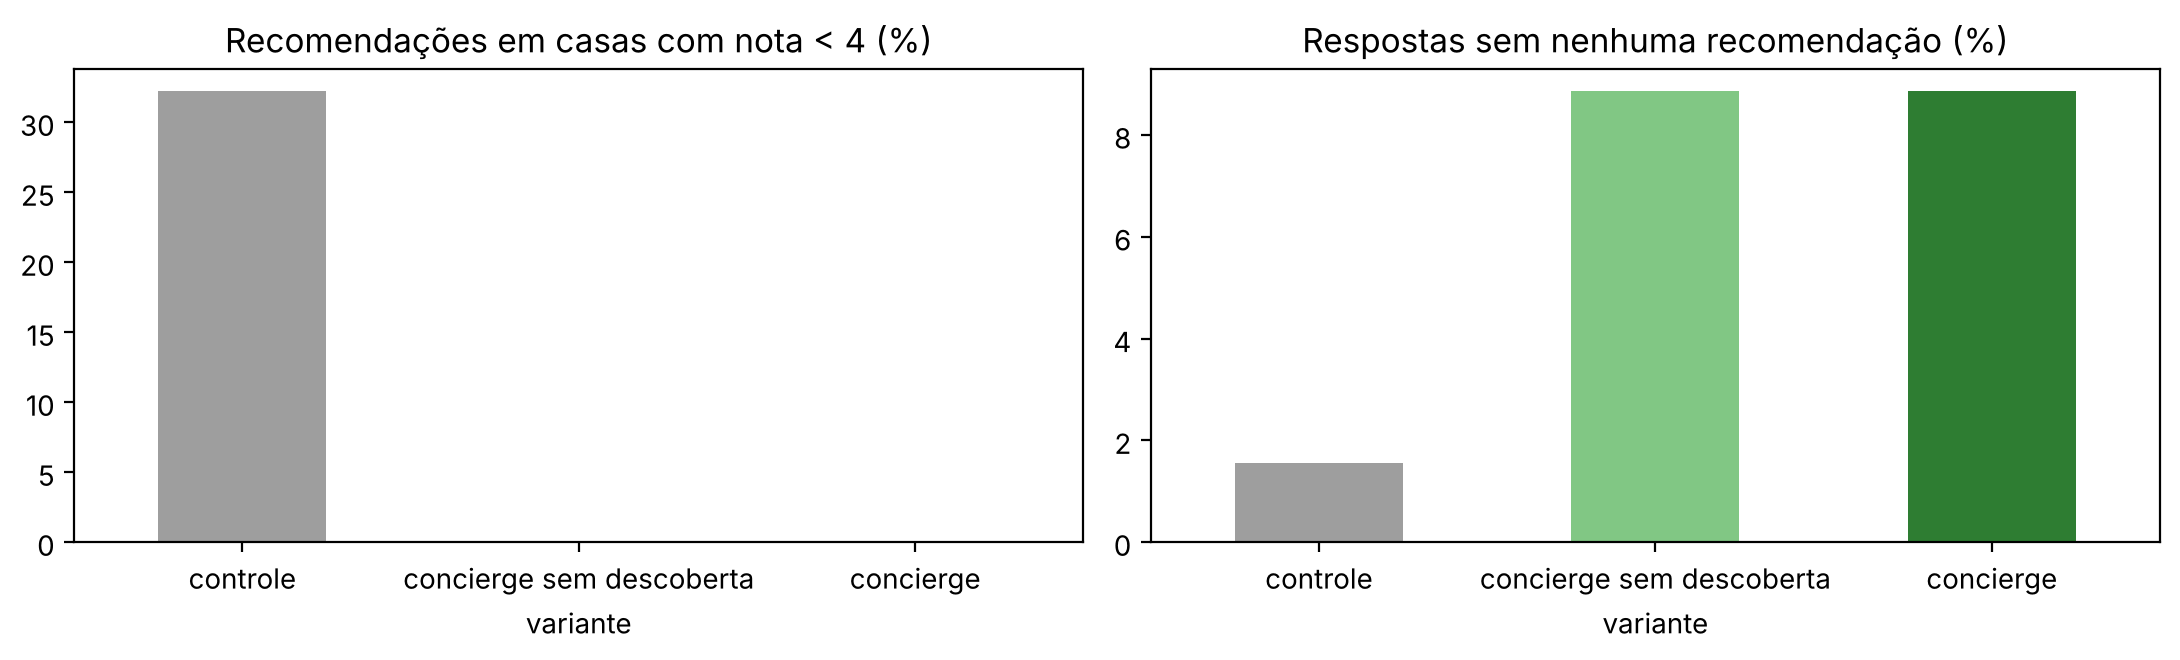

,recomendações,% em casa estabelecida com nota < 4,% em casa nova (< 20 avaliações),itens por lista,% de listas vazias,ruins a cada 1.000 recomendações
variante,,,,,,
controle,2683,32.2,0.3,4.7,1.6,320.9
concierge sem descoberta,2187,0.0,3.1,3.8,8.9,0.0
concierge,2187,0.0,4.7,3.8,8.9,0.0


In [4]:
estab = recs["review_count"] >= rec.MIN_AVALIACOES
bc = pd.DataFrame({
    "recomendações": recs.groupby("variante").size(),
    "% em casa estabelecida com nota < 4": 100 * recs[estab].assign(ruim=recs["stars"] < 4).groupby("variante")["ruim"].mean(),
    "% em casa nova (< 20 avaliações)": 100 * (~estab).groupby(recs["variante"]).mean(),
    "itens por lista": sessoes.groupby("variante")["itens"].mean(),
    "% de listas vazias": 100 * sessoes.assign(v=sessoes["itens"] == 0).groupby("variante")["v"].mean(),
}).loc[ORDEM]
bc["ruins a cada 1.000 recomendações"] = 10 * bc["% em casa estabelecida com nota < 4"] * (1 - bc["% em casa nova (< 20 avaliações)"] / 100)
bc.round(1).to_csv(SAIDA / "business_case.csv")

faixa_nova = [i for i in segA.index if i[0].startswith("menos de 20") and i[1] != "Cadastro"]
if faixa_nova:
    r = segA.loc[faixa_nova[0]]
    print(f"Casas novas: o modelo A tem precisão de {r['Precisão']:.1f}% e taxa de falso positivo de "
          f"{r['Taxa de FP (FP ÷ negativos)']:.1f}% nessa faixa ({int(r['restaurantes'])} restaurantes no teste).")
evitadas = bc.loc["controle", "ruins a cada 1.000 recomendações"] - bc.loc["concierge", "ruins a cada 1.000 recomendações"]
print(f"A cada 1.000 recomendações, o Concierge evita ≈{evitadas:.0f} indicações de casas mal avaliadas; "
      f"o custo é {bc.loc['concierge', '% de listas vazias'] - bc.loc['controle', '% de listas vazias']:+.1f} p.p. de listas vazias.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
bc["% em casa estabelecida com nota < 4"].plot.bar(ax=ax[0], color=["#9E9E9E", "#81C784", "#2E7D32"], rot=0)
ax[0].set_title("Recomendações em casas com nota < 4 (%)")
bc["% de listas vazias"].plot.bar(ax=ax[1], color=["#9E9E9E", "#81C784", "#2E7D32"], rot=0)
ax[1].set_title("Respostas sem nenhuma recomendação (%)")
plt.tight_layout(); plt.savefig(SAIDA / "business_case.png", dpi=120); plt.show()
bc.round(1)

### 3.1 Ajuste feito nesta fase: o piso do modelo B
Na primeira rodada com os dados reais, o top 5 usava o limiar cheio do modelo B (F0,5 no protocolo de 1 escolhido + 4
sorteados) **depois** da guarda de qualidade, e cerca de um quarto das respostas ficava sem nenhuma recomendação. O
diagnóstico: o falso positivo caro do BU (casa mal avaliada) já é barrado pela guarda, e o limiar cheio de B cortava
também casas boas por uma questão de gosto. A tabela testa pisos menores para B, mantendo tudo o mais igual, e junta a
precisão de B no teste com cada piso (do 03a). O piso adotado no app está marcado.

In [5]:
sensB = pd.read_csv(R03 / "B_limiar_sensibilidade.csv", index_col=0)
corte = rec.corte_movimento(tab)
mov = tab.set_index("business_id")["cand_chk_prev_log"]
linhas = []
for f in [1.0, 0.75, 0.5, 0.25, 0.0]:
    itens, baixos, total, ids = [], 0, 0, set()
    for pf in perfis:
        out = rec.recomendar(tab, art, fator_limiar_b=f, **pf)
        itens.append(len(out)); ids |= set(out["business_id"])
        baixos += int((mov.loc[out["business_id"]] <= corte).sum()); total += len(out)
    itens = np.array(itens)
    prec = sensB["Precisão"].iloc[[1.0, 0.75, 0.5, 0.25].index(f)] if f > 0 else np.nan
    linhas.append({"piso de B": f"{f:.0%} do limiar" + ("  <- app" if f == rec.FATOR_LIMIAR_B else ""),
                   "% de listas vazias": 100 * (itens == 0).mean(), "itens por lista": itens.mean(),
                   "restaurantes distintos indicados": len(ids),
                   "% das indicações na metade de menor movimento": 100 * baixos / max(total, 1),
                   "precisão de B no teste (%)": prec})
sens = pd.DataFrame(linhas).set_index("piso de B")
sens.round(1).to_csv(SAIDA / "sensibilidade_piso_B.csv")
sens.round(1)

,% de listas vazias,itens por lista,restaurantes distintos indicados,% das indicações na metade de menor movimento,precisão de B no teste (%)
piso de B,,,,,
100% do limiar,25.7,2.1,146,7.7,76.0
75% do limiar,12.7,3.0,189,10.8,65.8
50% do limiar <- app,8.9,3.8,227,14.2,55.5
25% do limiar,5.7,4.3,255,18.3,43.6
0% do limiar,4.2,4.4,272,21.9,NaN


## 4. Responsible AI
### 4.1 Viés para populares e cobertura
O BU listou o **viés para os populares** como risco de probabilidade alta: restaurantes pequenos quase não aparecem nos
apps. Medimos três coisas:
- **Cobertura:** quantos dos restaurantes elegíveis aparecem em pelo menos um top 5.
- **Exposição por porte:** quartis de movimento (check-ins até hoje). Se a fatia das recomendações num quartil for bem
  menor que a fatia desse quartil entre os candidatos, o produto esconde esse grupo.
- **Gini da exposição:** 0 = todos aparecem igual; 1 = um restaurante leva tudo.

**Mitigação testada:** o modelo B aprende que as pessoas vão mais aos lugares movimentados, então tende a repetir a
lista dos populares. A **vaga de descoberta** reserva o último lugar do top 5 para o restaurante de menor movimento
(metade inferior da cidade) com maior chance de escolha, desde que ele passe na guarda de qualidade. A comparação
"concierge sem descoberta" × "concierge" mostra o efeito.

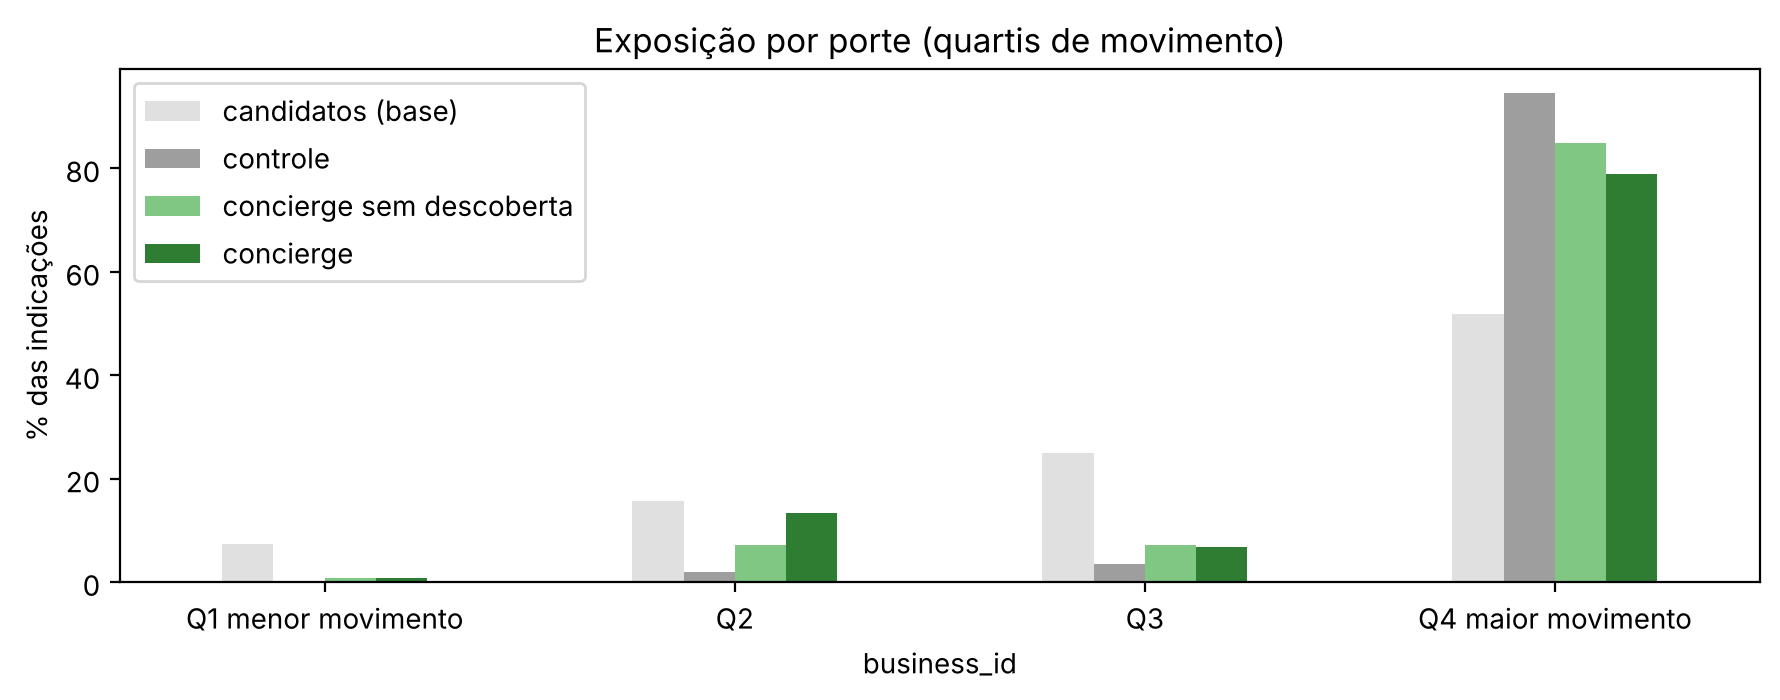

,cobertura do catálogo (%),Gini da exposição,% das indicações na metade de menor movimento
controle,14.682,0.940,2.013
concierge sem descoberta,16.289,0.934,7.865
concierge,16.581,0.933,14.220


,candidatos (base),controle,concierge sem descoberta,concierge
business_id,,,,
Q1 menor movimento,7.3,0.1,0.7,0.8
Q2,15.8,1.9,7.1,13.4
Q3,25.1,3.5,7.3,6.8
Q4 maior movimento,51.8,94.5,84.9,79.0


In [6]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())) if x.sum() > 0 else 0.0


abertos = tab[tab["is_open"] == 1]
cortes = abertos["cand_chk_prev_log"].quantile([0.25, 0.5, 0.75]).to_numpy()
ROT_Q = ["Q1 menor movimento", "Q2", "Q3", "Q4 maior movimento"]
quartil = pd.Series(pd.Categorical(np.array(ROT_Q)[np.searchsorted(cortes, tab["cand_chk_prev_log"], side="right")],
                                   categories=ROT_Q), index=tab["business_id"])

elegiveis = pool["business_id"].unique()
expo = pd.DataFrame({"candidatos (base)": pool["business_id"].map(quartil).value_counts(normalize=True)})
cob, gin = {}, {}
for var in ORDEM:
    r = recs[recs["variante"] == var]
    expo[var] = r["business_id"].map(quartil).value_counts(normalize=True)
    cob[var] = 100 * r["business_id"].nunique() / len(elegiveis)
    gin[var] = gini(r["business_id"].value_counts().reindex(elegiveis, fill_value=0))
expo = (100 * expo.reindex(ROT_Q).fillna(0))
expo.round(1).to_csv(SAIDA / "exposicao_por_porte.csv")

ax = expo.plot.bar(figsize=(9, 3.6), rot=0, color=["#E0E0E0", "#9E9E9E", "#81C784", "#2E7D32"])
ax.set_ylabel("% das indicações"); ax.set_title("Exposição por porte (quartis de movimento)")
plt.tight_layout(); plt.savefig(SAIDA / "exposicao_por_porte.png", dpi=120); plt.show()

rai = pd.DataFrame({"cobertura do catálogo (%)": cob, "Gini da exposição": gin,
                    "% das indicações na metade de menor movimento": expo.loc[["Q1 menor movimento", "Q2"], ORDEM].sum()})
rai.round(3).to_csv(SAIDA / "cobertura.csv")
display(rai.round(3))
expo.round(1)

### 4.2 Equidade geográfica: algum bairro fica sem resposta?

In [7]:
geo = (sessoes.assign(util=sessoes["itens"] >= 3)
       .pivot_table(index="bairro", columns="variante", values="util", aggfunc="mean")[ORDEM] * 100)
geo["candidatos médios"] = sessoes.groupby("bairro")["candidatos"].mean()
geo = geo.sort_values("concierge")
geo.round(1).to_csv(SAIDA / "equidade_bairros.csv")
print("% das respostas com pelo menos 3 recomendações, por bairro")
geo.round(1)

% das respostas com pelo menos 3 recomendações, por bairro


variante,controle,concierge sem descoberta,concierge,candidatos médios
bairro,,,,
Manayunk,69.4,5.6,5.6,6.1
Fishtown,95.8,69.4,69.4,36.4
South Philly,95.8,75.0,75.0,58.2
University City,95.8,76.4,76.4,59.9
Northern Liberties,95.8,87.5,87.5,73.5
Old City,95.8,93.1,93.1,84.2
Chinatown,95.8,94.4,94.4,91.7
Center City,95.8,95.8,95.8,96.1


### 4.3 Checklist de Responsible AI do Concierge

| Tema | O que o produto faz | Onde está |
|---|---|---|
| Dados pessoais e LGPD | não usa gênero, idade, raça nem renda; localização só por bairro e raio; questionário declarado pelo usuário | `recomendador.py`, app |
| Explicabilidade | cada recomendação vem com o motivo (culinária, preço, distância, nota ou aprovação prevista) | coluna `por que` |
| Viés para populares | medido acima (cobertura, exposição por porte, Gini) e comparado com a lista atual | seção 4.1 |
| Equidade geográfica | % de respostas úteis por bairro; bairros com poucos parceiros aparecem aqui | seção 4.2 |
| Vazamento e honestidade das métricas | atributos só com o passado, teste usado uma vez, probabilidade de A fora da amostra | 03a |
| Ciclo de retroalimentação | o feedback do app pode reforçar os já recomendados; o braço controle e a medida de cobertura no piloto servem de alarme | seção 5 |
| Restrições alimentares | alergias e restrições **não** entram no modelo nem viram dado salvo; o app avisa para confirmar com o restaurante | app |
| Generalização | o Yelp é dos EUA; no Brasil o cadastro dos parceiros substitui as colunas do Yelp e os modelos precisam ser retreinados | BU 1.2 |
| Supervisão humana | os limiares dos modelos são decisão de negócio documentada (F0,5) e podem ser revistos com o piloto | 03a |

## 5. Teste A/B do piloto (MVP 2)

| Item | Definição |
|---|---|
| Hipótese | o top 5 do Concierge gera mais escolhas que a lista atual (popularidade e nota) |
| Unidade de sorteio | usuário (hash do identificador), 50% controle e 50% concierge, fixo durante o teste |
| Métrica principal | **conversão da sessão**: sessões com pelo menos um "quero pedir/reservar" ÷ sessões com lista exibida |
| Secundárias | nota do feedback (1 a 5); posição do restaurante escolhido |
| Guardrails | % de listas vazias; queda de cobertura do catálogo |
| Decisão | teste bilateral, α = 5%, poder de 80%; só lê o resultado no fim do prazo (sem espiar) |
| Checagem de qualidade | *sample ratio mismatch*: a divisão observada precisa ser compatível com 50/50 |

### 5.1 Tamanho da amostra
A conversão do controle e o tráfego do piloto ainda não existem: os valores abaixo são **premissas** para planejar.
Basta trocar `P0` e `SESSOES_DIA` quando o MVP 1 tiver números.

In [8]:
P0 = 0.10            # premissa: conversão da lista atual
SESSOES_DIA = 400    # premissa: sessões por dia no piloto (somando os dois braços)


def n_por_braco(p0, mde_rel, alpha=0.05, poder=0.80):
    p1 = p0 * (1 + mde_rel)
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(poder)
    pm = (p0 + p1) / 2
    n = (za * np.sqrt(2 * pm * (1 - pm)) + zb * np.sqrt(p0 * (1 - p0) + p1 * (1 - p1))) ** 2 / (p1 - p0) ** 2
    return int(np.ceil(n))


plano = pd.DataFrame([{"conversão do controle": f"{p0:.0%}", "efeito mínimo (relativo)": f"+{m:.0%}",
                       "sessões por braço": n_por_braco(p0, m), "dias de teste": int(np.ceil(2 * n_por_braco(p0, m) / SESSOES_DIA))}
                      for p0 in [0.05, 0.10, 0.20] for m in [0.10, 0.20, 0.30]])
plano.to_csv(SAIDA / "ab_tamanho_amostra.csv", index=False)
N_PLANO = n_por_braco(P0, 0.20)
print(f"Plano escolhido: conversão de {P0:.0%} no controle, detectar +20% -> {N_PLANO:,} sessões por braço, "
      f"≈{np.ceil(2 * N_PLANO / SESSOES_DIA):.0f} dias com {SESSOES_DIA} sessões/dia.")
plano

Plano escolhido: conversão de 10% no controle, detectar +20% -> 3,841 sessões por braço, ≈20 dias com 400 sessões/dia.


,conversão do controle,efeito mínimo (relativo),sessões por braço,dias de teste
0,5%,+10%,31234,157
1,5%,+20%,8158,41
2,5%,+30%,3780,19
3,10%,+10%,14751,74
4,10%,+20%,3841,20
5,10%,+30%,1774,9
6,20%,+10%,6510,33
7,20%,+20%,1683,9
8,20%,+30%,772,4


### 5.2 Análise
A função abaixo lê o log no formato que o app grava (`logs/eventos.csv`: uma linha por evento `exibicao`, `clique` ou
`feedback`). Se o log ainda não existir ou for pequeno, a análise roda sobre um log **simulado**, só para mostrar o
procedimento; nesse caso o resultado não vale como evidência. Sessões em que a variante foi escolhida à mão na
barra lateral do app (`origem = manual`) ficam fora da análise.

In [9]:
def analisar_ab(ev):
    if "origem" in ev.columns:                      # sessões com variante escolhida à mão não entram no teste
        ev = ev[ev["origem"] != "manual"]
    exib = ev[ev["evento"] == "exibicao"].groupby(["sessao", "variante"], as_index=False)["n_itens"].max()
    conv = ev[ev["evento"] == "clique"].groupby("sessao").size().rename("cliques")
    s = exib.join(conv, on="sessao").fillna({"cliques": 0})
    s["converteu"] = (s["cliques"] > 0).astype(int)
    nota = ev[ev["evento"] == "feedback"].groupby("sessao")["nota"].mean()
    s = s.join(nota, on="sessao")
    g = s.groupby("variante").agg(sessoes=("converteu", "size"), conversoes=("converteu", "sum"),
                                  conversao=("converteu", "mean"), nota_media=("nota", "mean"),
                                  listas_vazias=("n_itens", lambda x: (x == 0).mean())).reindex(["controle", "concierge"])
    n0, n1 = g["sessoes"]
    c0, c1 = g["conversoes"]
    p0, p1 = c0 / n0, c1 / n1
    srm_p = stats.chisquare([n0, n1]).pvalue
    pp = (c0 + c1) / (n0 + n1)
    z = (p1 - p0) / np.sqrt(pp * (1 - pp) * (1 / n0 + 1 / n1))
    p_valor = 2 * (1 - stats.norm.cdf(abs(z)))
    ep = np.sqrt(p0 * (1 - p0) / n0 + p1 * (1 - p1) / n1)
    ic = (p1 - p0 - 1.96 * ep, p1 - p0 + 1.96 * ep)
    n_a, n_b = s.loc[s["variante"] == "concierge", "nota"].dropna(), s.loc[s["variante"] == "controle", "nota"].dropna()
    p_nota = stats.ttest_ind(n_a, n_b, equal_var=False).pvalue if min(len(n_a), len(n_b)) > 1 else np.nan
    return g, {"diferença (p.p.)": 100 * (p1 - p0), "IC 95% (p.p.)": (100 * ic[0], 100 * ic[1]),
               "p-valor conversão": p_valor, "p-valor nota": p_nota, "p-valor SRM": srm_p}


ev = pd.read_csv(LOG) if LOG.exists() else pd.DataFrame()
REAL = len(ev) > 0 and ev.loc[ev["evento"] == "exibicao", "sessao"].nunique() >= 200
if not REAL:
    rng = np.random.default_rng(SEED)
    vazias = sessoes.groupby("variante")["itens"].apply(lambda s: (s == 0).mean())
    linhas = []
    for k in range(2 * N_PLANO):
        var = "concierge" if rng.random() < 0.5 else "controle"
        vazia = rng.random() < vazias[var]
        linhas.append({"sessao": f"s{k}", "variante": var, "evento": "exibicao", "n_itens": 0 if vazia else 5, "nota": np.nan})
        p = 0 if vazia else min(1.0, (P0 * 1.2 if var == "concierge" else P0) / (1 - vazias[var]))  # efeito simulado: +20%
        if rng.random() < p:
            linhas.append({"sessao": f"s{k}", "variante": var, "evento": "clique", "n_itens": np.nan, "nota": np.nan})
        if rng.random() < 0.3 and not vazia:
            linhas.append({"sessao": f"s{k}", "variante": var, "evento": "feedback", "n_itens": np.nan,
                           "nota": float(np.clip(np.round(rng.normal(4.0 if var == "concierge" else 3.8, 0.9)), 1, 5))})
    ev = pd.DataFrame(linhas)

g, teste = analisar_ab(ev)
print("Fonte:", "log do app (logs/eventos.csv)" if REAL else "LOG SIMULADO (efeito de +20% colocado de propósito; não é evidência)")
print(f"SRM: p = {teste['p-valor SRM']:.3f} -> {'divisão ok' if teste['p-valor SRM'] > 0.01 else 'divisão suspeita: checar o sorteio antes de ler o resultado'}")
print(f"Conversão: {teste['diferença (p.p.)']:+.2f} p.p. (IC 95%: {teste['IC 95% (p.p.)'][0]:+.2f} a {teste['IC 95% (p.p.)'][1]:+.2f}), "
      f"p = {teste['p-valor conversão']:.4f}")
print(f"Nota do feedback: p = {teste['p-valor nota']:.4f}")
g.round(3)

Fonte: LOG SIMULADO (efeito de +20% colocado de propósito; não é evidência)
SRM: p = 0.273 -> divisão ok
Conversão: +2.81 p.p. (IC 95%: +1.43 a +4.18), p = 0.0001
Nota do feedback: p = 0.0000


,sessoes,conversoes,conversao,nota_media,listas_vazias
variante,,,,,
controle,3793,350,0.092,3.750,0.015
concierge,3889,468,0.120,3.985,0.083


## 6. Decisão (CRISP-DM, Fase 5)
A célula escreve a conclusão a partir dos números, para continuar correta quando a base ou o log mudarem.

In [10]:
b_ok = (resumoB.loc[art["nome_B"], "MRR"] > resumoB.loc["Popularidade (check-ins até a data)", "MRR"]
        and resumoB.loc[art["nome_B"], "AUC"] > resumoB.loc["Popularidade (check-ins até a data)", "AUC"])
a_ok = resumoA.iloc[0]["AUC"] > resumoA.loc["Popularidade (check-ins)", "AUC"]
fp_ok = bc.loc["concierge", "ruins a cada 1.000 recomendações"] < bc.loc["controle", "ruins a cada 1.000 recomendações"]
vazia_ok = bc.loc["concierge", "% de listas vazias"] <= 25
cob_ok = (rai.loc["concierge", "% das indicações na metade de menor movimento"]
          >= rai.loc["controle", "% das indicações na metade de menor movimento"])

checks = pd.Series({
    "Modelo A supera a popularidade (AUC)": a_ok,
    "Modelo B supera a popularidade (AUC e MRR)": b_ok,
    "Menos indicações de casas mal avaliadas que o controle": fp_ok,
    "Guardrail: até 25% de respostas sem recomendação": vazia_ok,
    "Restaurantes de menor movimento não perdem espaço frente ao controle": cob_ok,
}, name="ok")
display(checks.map({True: "sim", False: "não"}).to_frame())
if a_ok and b_ok and fp_ok and vazia_ok:
    print("Decisão: seguir para a Fase 6 (deploy do app e piloto A/B)." + ("" if cob_ok else
          " Ponto de atenção: o top 5 concentra mais nos restaurantes movimentados; acompanhar a cobertura no piloto."))
elif not vazia_ok:
    print("Decisão: voltar à Fase 3/4: a guarda de qualidade deixa respostas demais sem recomendação (rever limiares ou raio).")
else:
    print("Decisão: voltar à Fase 3 no item que falhou.")

,ok
Modelo A supera a popularidade (AUC),sim
Modelo B supera a popularidade (AUC e MRR),sim
Menos indicações de casas mal avaliadas que o controle,sim
Guardrail: até 25% de respostas sem recomendação,sim
Restaurantes de menor movimento não perdem espaço frente ao controle,sim


Decisão: seguir para a Fase 6 (deploy do app e piloto A/B).
